In [5]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [6]:
print("Hello! Python is working")

Hello! Python is working


In [7]:

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the dataset file
files = glob.glob('/kaggle/input/**/manufacturing.csv', recursive=True)

if not files:
    raise FileNotFoundError("manufacturing.csv was not found!")

# Load dataset
df = pd.read_csv(files[0])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nColumn Names:")
print(df.columns.tolist())


Dataset loaded successfully!
Dataset shape: (3957, 6)

First 5 rows:


,Temperature (°C),Pressure (kPa),Temperature x Pressure,Material Fusion Metric,Material Transformation Metric,Quality Rating
0,209.762701,8.050855,1688.769167,44522.217074,9.229576e+06,99.999971
1,243.037873,15.812068,3842.931469,63020.764997,1.435537e+07,99.985703
2,220.552675,7.843130,1729.823314,49125.950249,1.072839e+07,99.999758
3,208.976637,23.786089,4970.736918,57128.881547,9.125702e+06,99.999975
4,184.730960,15.797812,2918.345014,38068.201283,6.303792e+06,100.000000



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3957 entries, 0 to 3956
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Temperature (°C)                3957 non-null   float64
 1   Pressure (kPa)                  3957 non-null   float64
 2   Temperature x Pressure          3957 non-null   float64
 3   Material Fusion Metric          3957 non-null   float64
 4   Material Transformation Metric  3957 non-null   float64
 5   Quality Rating                  3957 non-null   float64
dtypes: float64(6)
memory usage: 185.6 KB

Statistical Summary:


,Temperature (°C),Pressure (kPa),Temperature x Pressure,Material Fusion Metric,Material Transformation Metric,Quality Rating
count,3957.000000,3957.000000,3957.000000,3957.000000,3.957000e+03,3957.000000
mean,200.034704,14.815558,2955.321308,48127.183128,1.003645e+07,96.260179
std,58.135717,5.772040,1458.224940,23812.213513,7.599356e+06,12.992262
min,100.014490,5.003008,513.706875,10156.971955,9.999462e+05,1.000000
25%,150.871296,9.692984,1798.247303,27626.929091,3.433810e+06,99.941129
50%,198.603371,14.832557,2678.277782,44611.452164,7.833390e+06,99.999997
75%,251.366552,19.749680,3929.058261,67805.443846,1.588251e+07,100.000000
max,299.992804,24.999132,7365.018714,103756.181544,2.699783e+07,100.000000



Missing Values:
Temperature (°C)                  0
Pressure (kPa)                    0
Temperature x Pressure            0
Material Fusion Metric            0
Material Transformation Metric    0
Quality Rating                    0
dtype: int64

Duplicate Rows: 0

Column Names:
['Temperature (°C)', 'Pressure (kPa)', 'Temperature x Pressure', 'Material Fusion Metric', 'Material Transformation Metric', 'Quality Rating']


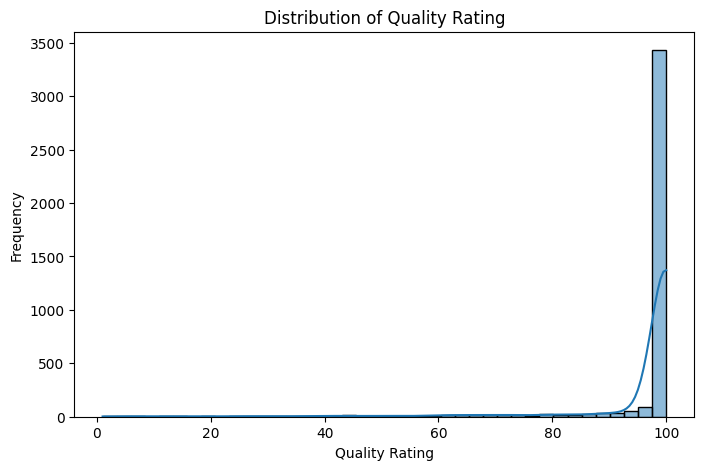

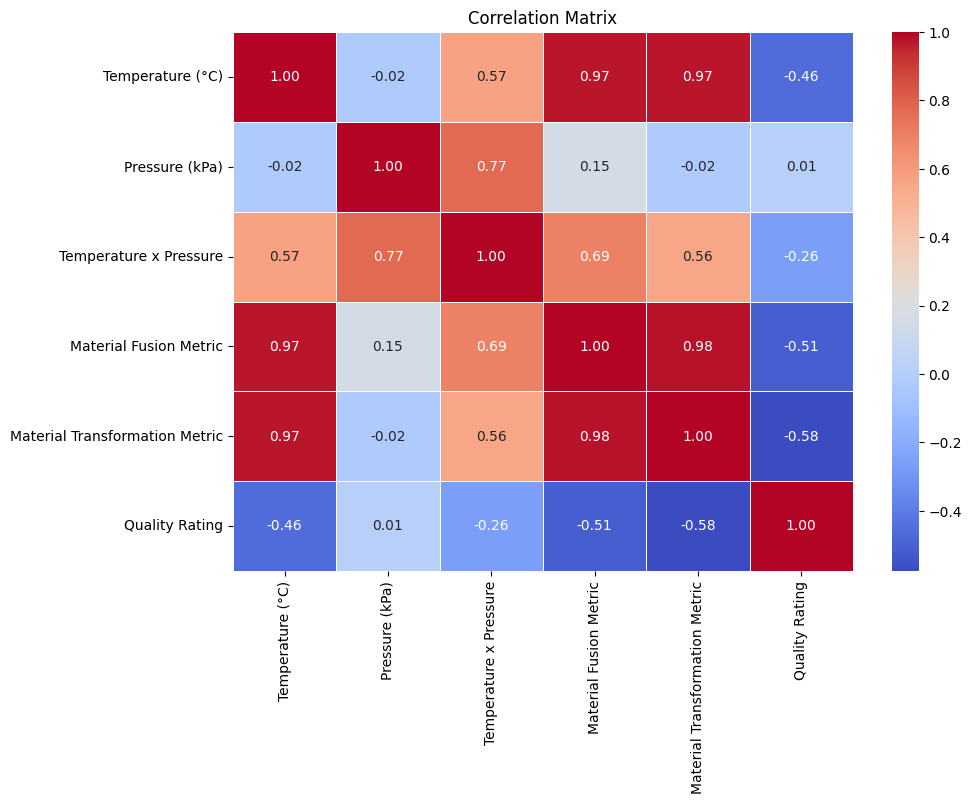

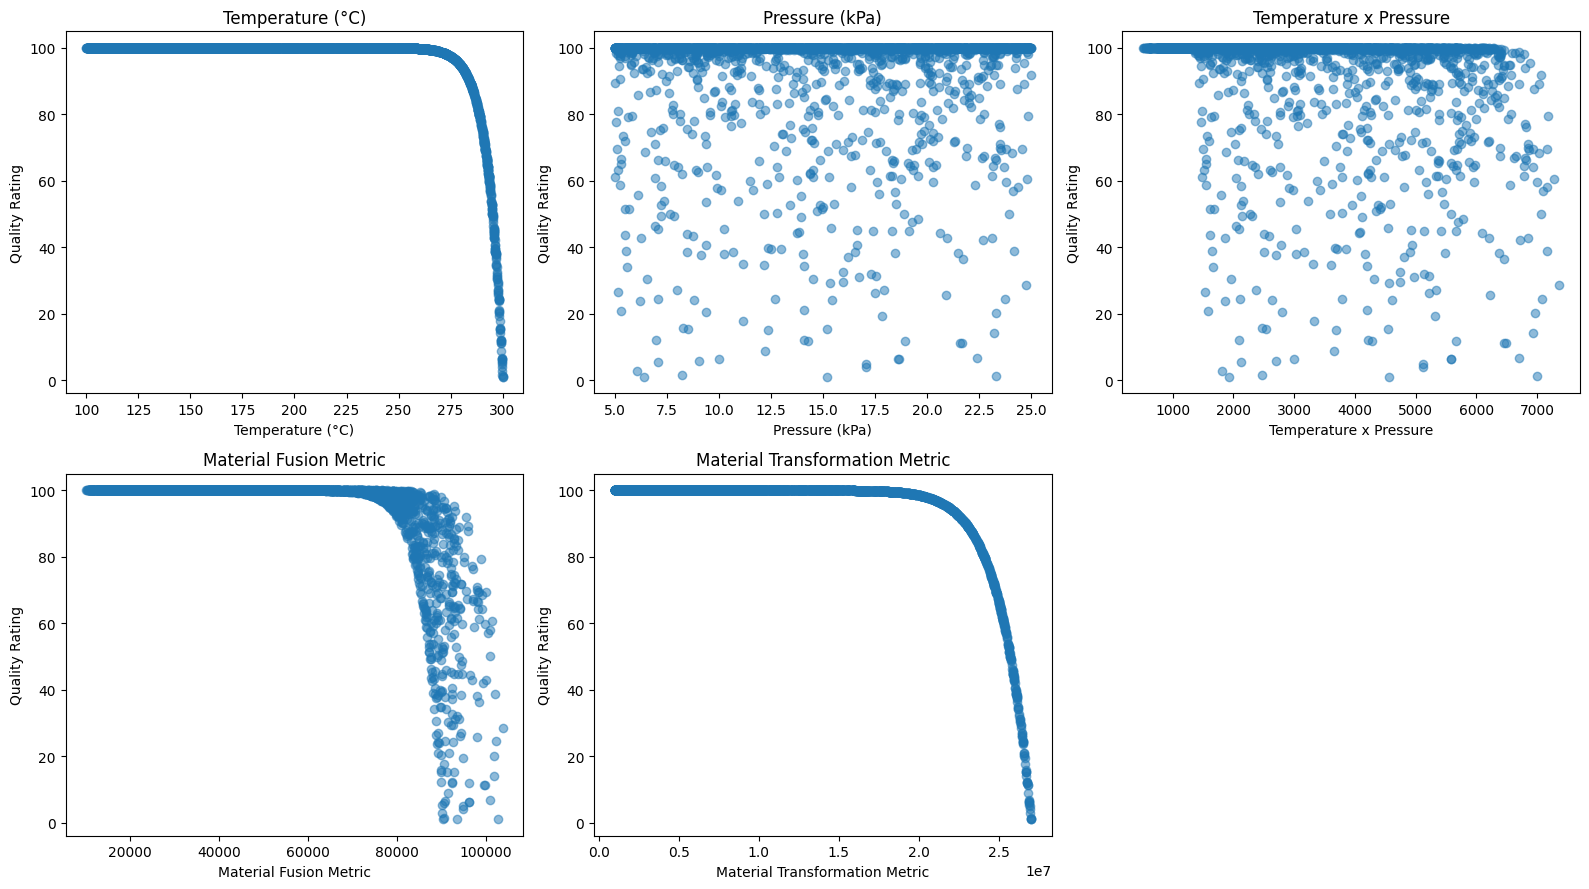

Target Statistics:
count    3957.000000
mean       96.260179
std        12.992262
min         1.000000
25%        99.941129
50%        99.999997
75%       100.000000
max       100.000000
Name: Quality Rating, dtype: float64

Number of unique target values:
3187


In [8]:

# ==========================================
# Exploratory Data Analysis (EDA)
# ==========================================

# 1. Target distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['Quality Rating'], bins=40, kde=True)
plt.title('Distribution of Quality Rating')
plt.xlabel('Quality Rating')
plt.ylabel('Frequency')
plt.show()


# 2. Correlation Matrix
plt.figure(figsize=(10, 7))
correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix')
plt.show()


# 3. Features vs Target
features = [
    'Temperature (°C)',
    'Pressure (kPa)',
    'Temperature x Pressure',
    'Material Fusion Metric',
    'Material Transformation Metric'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feature in enumerate(features):
    axes[i].scatter(
        df[feature],
        df['Quality Rating'],
        alpha=0.5
    )
    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Quality Rating')

axes[-1].axis('off')

plt.tight_layout()
plt.show()


# 4. Target statistics
print("Target Statistics:")
print(df['Quality Rating'].describe())

print("\nNumber of unique target values:")
print(df['Quality Rating'].nunique())


In [9]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

# Select input features
X = df[
    [
        'Temperature (°C)',
        'Pressure (kPa)',
        'Material Fusion Metric',
        'Material Transformation Metric'
    ]
].values

# Select target
y = df['Quality Rating'].values.reshape(-1, 1)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Scale original input features
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Generate Polynomial Features
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

# Scale polynomial features
scaler_poly = StandardScaler()

X_train_poly = scaler_poly.fit_transform(X_train_poly)
X_test_poly = scaler_poly.transform(X_test_poly)

# Scale target values
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train).ravel()
y_test_scaled = scaler_y.transform(y_test).ravel()

print("Data preparation completed!")

print("Original training shape:", X_train.shape)
print("Polynomial training shape:", X_train_poly.shape)

print("Original testing shape:", X_test.shape)
print("Polynomial testing shape:", X_test_poly.shape)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Polynomial features:", X_train_poly.shape[1])


Data preparation completed!
Original training shape: (3165, 4)
Polynomial training shape: (3165, 14)
Original testing shape: (792, 4)
Polynomial testing shape: (792, 14)
Training samples: 3165
Testing samples: 792
Polynomial features: 14


In [10]:

# Check target distribution in detail

print("Percentage of samples in each target range:")

ranges = [
    (0, 50),
    (50, 80),
    (80, 90),
    (90, 95),
    (95, 99),
    (99, 100.000001)
]

for low, high in ranges:
    count = ((df['Quality Rating'] >= low) &
             (df['Quality Rating'] < high)).sum()

    percentage = count / len(df) * 100

    print(f"{low} - {high}: {count} samples ({percentage:.2f}%)")


# Compare with a simple baseline model

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

baseline = DummyRegressor(strategy='mean')

baseline.fit(X_train_poly, y_train_scaled)

baseline_pred = baseline.predict(X_test_poly)

print("\nBaseline Model Results:")
print("MSE:", mean_squared_error(y_test_scaled, baseline_pred))
print("R2:", r2_score(y_test_scaled, baseline_pred))


Percentage of samples in each target range:
0 - 50: 98 samples (2.48%)
50 - 80: 161 samples (4.07%)
80 - 90: 93 samples (2.35%)
90 - 95: 86 samples (2.17%)
95 - 99: 198 samples (5.00%)
99 - 100.000001: 3321 samples (83.93%)

Baseline Model Results:
MSE: 1.2783336394461176
R2: -0.0009905958440956653


In [11]:
import glob
import pandas as pd

files = glob.glob('/kaggle/input/**/*.csv', recursive=True)

for file in files:
    print(file)

df = pd.read_csv(files[0])

print("\nDataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

/kaggle/input/datasets/niteshyadav3103/concrete-compressive-strength/Concrete Compressive Strength.csv
/kaggle/input/datasets/rukenmissonnier/manufacturing-data-for-polynomial-regression/manufacturing.csv

Dataset shape: (1030, 9)

Columns:
['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age (day)', 'Concrete compressive strength ']

First 5 rows:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age (day),Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075



Missing values:
Cement                            0
Blast Furnace Slag                0
Fly Ash                           0
Water                             0
Superplasticizer                  0
Coarse Aggregate                  0
Fine Aggregate                    0
Age (day)                         0
Concrete compressive strength     0
dtype: int64


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

# Separate features and target
X = df.drop(columns=['Concrete compressive strength ']).values
y = df['Concrete compressive strength '].values.reshape(-1, 1)

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale original features
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Scale target
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

# Create polynomial features (degree 2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print("Original training shape:", X_train.shape)
print("Polynomial training shape:", X_train_poly.shape)
print("Testing shape:", X_test_poly.shape)
print("Target shape:", y_train_scaled.shape)

Original training shape: (824, 8)
Polynomial training shape: (824, 44)
Testing shape: (206, 44)
Target shape: (824, 1)


## 3. Implementing Optimization Algorithms from Scratch

In [23]:
# Linear Regression Model and Loss Function

def predict(X, weights, bias):
    return X @ weights + bias


def compute_loss(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)


def compute_gradients(X, y, weights, bias):
    m = X.shape[0]

    predictions = predict(X, weights, bias)
    errors = predictions - y

    dw = (2 / m) * (X.T @ errors)
    db = (2 / m) * np.sum(errors)

    return dw, db

In [24]:
print("Linear Regression functions are ready!")

Linear Regression functions are ready!


## 4. Gradient Descent with Momentum

In [25]:
def train_gd_momentum(X, y, learning_rate=0.01,
                      momentum=0.9, epochs=1000):

    m, n = X.shape

    weights = np.zeros((n, 1))
    bias = 0.0

    velocity_w = np.zeros_like(weights)
    velocity_b = 0.0

    loss_history = []

    for epoch in range(epochs):

        dw, db = compute_gradients(X, y, weights, bias)

        # Momentum update
        velocity_w = momentum * velocity_w + dw
        velocity_b = momentum * velocity_b + db

        # Update parameters
        weights -= learning_rate * velocity_w
        bias -= learning_rate * velocity_b

        # Calculate loss
        predictions = predict(X, weights, bias)
        loss = compute_loss(y, predictions)

        loss_history.append(loss)

    return weights, bias, loss_history


# Train the model
gd_weights, gd_bias, gd_loss = train_gd_momentum(
    X_train_poly,
    y_train_scaled
)

print("Gradient Descent with Momentum")
print("Final Training Loss:", gd_loss[-1])

Gradient Descent with Momentum
Final Training Loss: 0.18882647375403835


## 5. Stochastic Gradient Descent (SGD)

In [26]:
def train_sgd(X, y, learning_rate=0.001, epochs=100):

    m, n = X.shape

    weights = np.zeros((n, 1))
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        indices = np.random.permutation(m)

        for i in indices:
            xi = X[i:i+1]
            yi = y[i:i+1]

            dw, db = compute_gradients(xi, yi, weights, bias)

            weights -= learning_rate * dw
            bias -= learning_rate * db

        predictions = predict(X, weights, bias)
        loss_history.append(compute_loss(y, predictions))

    return weights, bias, loss_history


sgd_weights, sgd_bias, sgd_loss = train_sgd(
    X_train_poly,
    y_train_scaled
)

print("Stochastic Gradient Descent")
print("Final Training Loss:", sgd_loss[-1])

Stochastic Gradient Descent
Final Training Loss: 0.23941139838317335


## 6. Mini-Batch Gradient Descent

In [27]:
def train_minibatch(X, y, learning_rate=0.01,
                    batch_size=32, epochs=200):

    m, n = X.shape

    weights = np.zeros((n, 1))
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        indices = np.random.permutation(m)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, m, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            dw, db = compute_gradients(
                X_batch, y_batch, weights, bias
            )

            weights -= learning_rate * dw
            bias -= learning_rate * db

        predictions = predict(X, weights, bias)
        loss_history.append(compute_loss(y, predictions))

    return weights, bias, loss_history


mb_weights, mb_bias, mb_loss = train_minibatch(
    X_train_poly,
    y_train_scaled
)

print("Mini-Batch Gradient Descent")
print("Final Training Loss:", mb_loss[-1])

Mini-Batch Gradient Descent
Final Training Loss: 0.19348587827760397


## 7. RMSProp Optimizer

In [28]:
def train_rmsprop(X, y, learning_rate=0.001,
                  beta=0.9, epsilon=1e-8, epochs=1000):

    m, n = X.shape

    weights = np.zeros((n, 1))
    bias = 0.0

    squared_grad_w = np.zeros_like(weights)
    squared_grad_b = 0.0

    loss_history = []

    for epoch in range(epochs):

        dw, db = compute_gradients(X, y, weights, bias)

        squared_grad_w = beta * squared_grad_w + (1 - beta) * (dw ** 2)
        squared_grad_b = beta * squared_grad_b + (1 - beta) * (db ** 2)

        weights -= learning_rate * dw / (np.sqrt(squared_grad_w) + epsilon)
        bias -= learning_rate * db / (np.sqrt(squared_grad_b) + epsilon)

        predictions = predict(X, weights, bias)
        loss_history.append(compute_loss(y, predictions))

    return weights, bias, loss_history


rms_weights, rms_bias, rms_loss = train_rmsprop(
    X_train_poly,
    y_train_scaled
)

print("RMSProp Optimizer")
print("Final Training Loss:", rms_loss[-1])

RMSProp Optimizer
Final Training Loss: 0.19109805361117044


## 8. Adam Optimizer

In [29]:
def train_adam(X, y, learning_rate=0.001,
               beta1=0.9, beta2=0.999,
               epsilon=1e-8, epochs=1000):

    m, n = X.shape

    weights = np.zeros((n, 1))
    bias = 0.0

    mw = np.zeros_like(weights)
    vw = np.zeros_like(weights)

    mb = 0.0
    vb = 0.0

    loss_history = []

    for t in range(1, epochs + 1):

        dw, db = compute_gradients(X, y, weights, bias)

        mw = beta1 * mw + (1 - beta1) * dw
        vw = beta2 * vw + (1 - beta2) * (dw ** 2)

        mb = beta1 * mb + (1 - beta1) * db
        vb = beta2 * vb + (1 - beta2) * (db ** 2)

        mw_corrected = mw / (1 - beta1 ** t)
        vw_corrected = vw / (1 - beta2 ** t)

        mb_corrected = mb / (1 - beta1 ** t)
        vb_corrected = vb / (1 - beta2 ** t)

        weights -= learning_rate * mw_corrected / (
            np.sqrt(vw_corrected) + epsilon
        )

        bias -= learning_rate * mb_corrected / (
            np.sqrt(vb_corrected) + epsilon
        )

        predictions = predict(X, weights, bias)
        loss_history.append(compute_loss(y, predictions))

    return weights, bias, loss_history


adam_weights, adam_bias, adam_loss = train_adam(
    X_train_poly,
    y_train_scaled
)

print("Adam Optimizer")
print("Final Training Loss:", adam_loss[-1])

Adam Optimizer
Final Training Loss: 0.22427791460034865


## 9. Model Evaluation and Comparison

In [30]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pandas as pd
import numpy as np

models = {
    "GD with Momentum": (gd_weights, gd_bias),
    "SGD": (sgd_weights, sgd_bias),
    "Mini-Batch GD": (mb_weights, mb_bias),
    "RMSProp": (rms_weights, rms_bias),
    "Adam": (adam_weights, adam_bias)
}

results = []

for name, (weights, bias) in models.items():

    predictions_scaled = predict(X_test_poly, weights, bias)

    predictions = scaler_y.inverse_transform(predictions_scaled)
    actual = scaler_y.inverse_transform(y_test_scaled)

    mse = mean_squared_error(actual, predictions)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(actual, predictions)
    r2 = r2_score(actual, predictions)

    results.append({
        "Optimizer": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Optimizer,MSE,RMSE,MAE,R2 Score
0,GD with Momentum,55.1723,7.4278,5.9650,0.7859
1,SGD,77.5937,8.8087,6.6731,0.6989
2,Mini-Batch GD,56.7179,7.5311,6.0048,0.7799
3,RMSProp,55.0620,7.4204,5.9621,0.7863
4,Adam,62.9763,7.9358,6.4454,0.7556


## 10. Linear Regression vs Polynomial Regression

In [31]:
# Train Linear Regression using RMSProp
linear_weights, linear_bias, linear_loss = train_rmsprop(
    X_train_scaled,
    y_train_scaled
)

# Evaluate Linear Regression
linear_predictions_scaled = predict(
    X_test_scaled, linear_weights, linear_bias
)

linear_predictions = scaler_y.inverse_transform(
    linear_predictions_scaled
)

actual = scaler_y.inverse_transform(y_test_scaled)

linear_mse = mean_squared_error(actual, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_mae = mean_absolute_error(actual, linear_predictions)
linear_r2 = r2_score(actual, linear_predictions)

# Best Polynomial Regression: RMSProp
poly_predictions_scaled = predict(
    X_test_poly, rms_weights, rms_bias
)

poly_predictions = scaler_y.inverse_transform(
    poly_predictions_scaled
)

poly_mse = mean_squared_error(actual, poly_predictions)
poly_rmse = np.sqrt(poly_mse)
poly_mae = mean_absolute_error(actual, poly_predictions)
poly_r2 = r2_score(actual, poly_predictions)

comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MSE": linear_mse,
        "RMSE": linear_rmse,
        "MAE": linear_mae,
        "R2 Score": linear_r2
    },
    {
        "Model": "Polynomial Regression",
        "MSE": poly_mse,
        "RMSE": poly_rmse,
        "MAE": poly_mae,
        "R2 Score": poly_r2
    }
])

display(comparison.round(4))

,Model,MSE,RMSE,MAE,R2 Score
0,Linear Regression,95.8286,9.7892,7.7428,0.6281
1,Polynomial Regression,55.0620,7.4204,5.9621,0.7863


## 11. Results Visualization

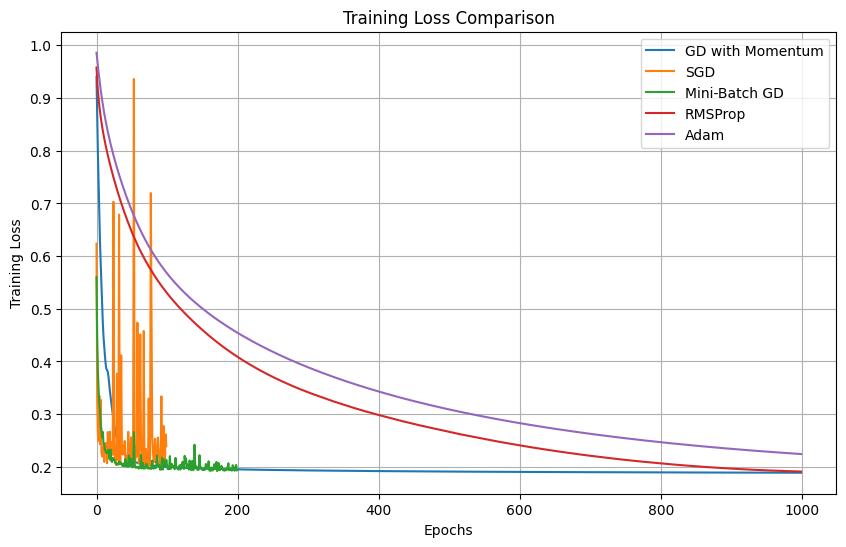

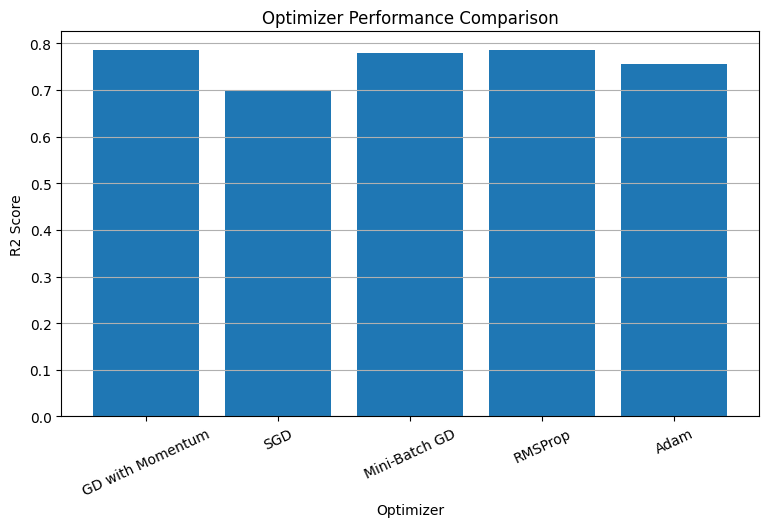

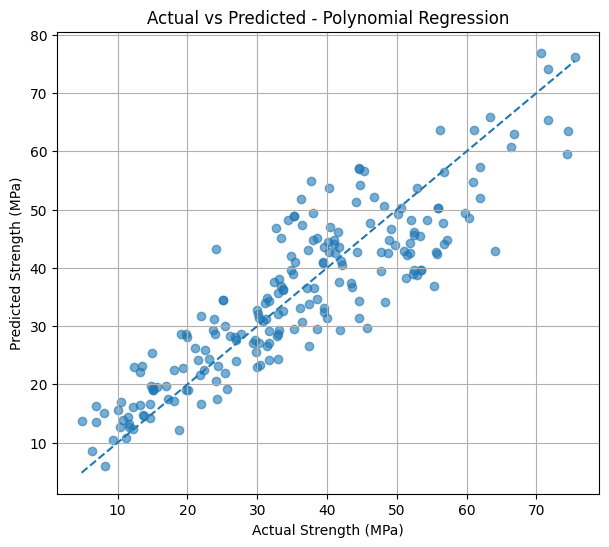

In [32]:
import matplotlib.pyplot as plt

# 1. Training Loss Comparison
plt.figure(figsize=(10, 6))

plt.plot(gd_loss, label="GD with Momentum")
plt.plot(sgd_loss, label="SGD")
plt.plot(mb_loss, label="Mini-Batch GD")
plt.plot(rms_loss, label="RMSProp")
plt.plot(adam_loss, label="Adam")

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()


# 2. R2 Score Comparison
plt.figure(figsize=(9, 5))

plt.bar(results_df["Optimizer"], results_df["R2 Score"])

plt.xlabel("Optimizer")
plt.ylabel("R2 Score")
plt.title("Optimizer Performance Comparison")
plt.xticks(rotation=25)
plt.grid(axis="y")
plt.show()


# 3. Actual vs Predicted Values
plt.figure(figsize=(7, 6))

plt.scatter(actual, poly_predictions, alpha=0.6)

plt.plot(
    [actual.min(), actual.max()],
    [actual.min(), actual.max()],
    linestyle="--"
)

plt.xlabel("Actual Strength (MPa)")
plt.ylabel("Predicted Strength (MPa)")
plt.title("Actual vs Predicted - Polynomial Regression")
plt.grid(True)
plt.show()

## 12. Conclusion

This project implemented Linear Regression and Polynomial Regression
using five optimization algorithms from scratch: GD with Momentum,
SGD, Mini-Batch Gradient Descent, RMSProp, and Adam.

The Concrete Compressive Strength dataset was used to predict concrete
strength based on its ingredients and age.

The experimental results showed that Polynomial Regression performed
better than Linear Regression.

Polynomial Regression achieved an R2 score of 0.7863, compared to
0.6281 for Linear Regression.

Among the five optimizers, RMSProp achieved the best test performance
with an R2 score of 0.7863.

The results demonstrate the importance of feature transformation
and optimizer selection in regression problems.

## 13. Dataset Description

The Concrete Compressive Strength dataset contains 1030 observations
and 9 numerical columns.

It includes 8 input features:

1. Cement
2. Blast Furnace Slag
3. Fly Ash
4. Water
5. Superplasticizer
6. Coarse Aggregate
7. Fine Aggregate
8. Age (day)

The target variable is Concrete Compressive Strength, measured in MPa.

The dataset contains no missing values.

The objective is to predict concrete compressive strength based on
the quantities of its ingredients and its age.

## 14. Data Preprocessing

The dataset was loaded using Pandas and checked for missing values.

The input features were separated from the target variable.

The dataset was divided into 80% training data and 20% testing data
using a random state of 42.

StandardScaler was applied to normalize the input features and target.

PolynomialFeatures with degree 2 was used to generate polynomial
features, increasing the number of input features from 8 to 44.

The same preprocessing transformations were applied to training
and testing data to avoid data leakage.

## 15. Optimization Algorithms

Five optimization algorithms were implemented from scratch using NumPy
to train the regression models.

### 1. Gradient Descent with Momentum (GD)

Gradient Descent updates model parameters using the gradients
calculated from the entire training dataset.

Momentum uses previous updates to accelerate convergence and
reduce oscillations.

### 2. Stochastic Gradient Descent (SGD)

SGD updates model parameters using one randomly selected training
sample at a time.

It can provide frequent updates but may produce noisy convergence.

### 3. Mini-Batch Gradient Descent

Mini-Batch Gradient Descent divides the training dataset into
small batches.

It updates model parameters after processing each batch,
combining advantages of GD and SGD.

### 4. RMSProp

RMSProp adapts the learning rate for each parameter using an
exponential moving average of squared gradients.

This helps improve optimization stability.

### 5. Adam

Adam combines momentum-based first-moment estimates with
adaptive second-moment estimates.

It also applies bias correction to the moment estimates.

### Momentum Concept

Momentum is an optimization technique that uses information
from previous gradients to improve the direction and speed
of parameter updates.

It can help accelerate convergence and reduce oscillations
during training.

## 16. References

1. Concrete Compressive Strength Dataset:
   https://www.kaggle.com/datasets/niteshyadav3103/concrete-compressive-strength

2. NumPy Documentation:
   https://numpy.org/doc/

3. Pandas Documentation:
   https://pandas.pydata.org/docs/

4. Scikit-learn Documentation:
   https://scikit-learn.org/stable/